# Text categories

Models need numbers, but the **country** column holds words. This notebook turns it into numbers two ways: label encoding and one-hot encoding.

This notebook goes with the **Text categories** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

## 1. Load the data

`customers.csv` is a small made-up table of 80 shoppers: their **country**, **age** and **salary**, and whether they **purchased** (1) or not (0). It was generated for this course, so it is free to use. A few ages and salaries are left blank on purpose.

In [1]:
import numpy as np
import pandas as pd

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/customers.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,country,age,salary,purchased
0,Spain,37.0,49000.0,0
1,France,49.0,52000.0,1
2,France,37.0,35000.0,0
3,Germany,33.0,56500.0,1
4,Germany,24.0,29500.0,0


## 2. Label encoding

`LabelEncoder` gives each country a number, in A to Z order. That is one column and easy to read, but notice what the numbers say.

In [2]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
codes = le.fit_transform(dataset['country'])
for code_, name in enumerate(le.classes_):
    print(code_, '=', name)

print()
print(dataset['country'].head(5).tolist())
print(codes[:5])

0 = France
1 = Germany
2 = Spain

['Spain', 'France', 'France', 'Germany', 'Germany']
[2 0 0 1 1]


**The catch:** 2 is bigger than 0, and the gap between 0 and 2 is twice the gap between 0 and 1. A model that works with distances will read that as 'Spain is twice as far from France as Germany is'. Countries have no such order.

## 3. One-hot encoding

`OneHotEncoder` makes one 0/1 column per country. Every country is now the same distance from every other.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X = dataset[['country', 'age', 'salary']]
ct = ColumnTransformer([('country', OneHotEncoder(), ['country'])], remainder='passthrough')
encoded = ct.fit_transform(X)

print(ct.get_feature_names_out())
print(encoded[:5])

['country__country_France' 'country__country_Germany'
 'country__country_Spain' 'remainder__age' 'remainder__salary']
[[0.00e+00 0.00e+00 1.00e+00 3.70e+01 4.90e+04]
 [1.00e+00 0.00e+00 0.00e+00 4.90e+01 5.20e+04]
 [1.00e+00 0.00e+00 0.00e+00 3.70e+01 3.50e+04]
 [0.00e+00 1.00e+00 0.00e+00 3.30e+01 5.65e+04]
 [0.00e+00 1.00e+00 0.00e+00 2.40e+01 2.95e+04]]


The first three columns are France, Germany and Spain. Each row has exactly one 1 among them. The `age` and `salary` columns pass through unchanged (and still have blanks: fix them with the missing-values lesson).

## 4. The same idea in one line of pandas

`pd.get_dummies` does one-hot encoding on a DataFrame column.

In [4]:
pd.get_dummies(dataset['country'], dtype=int).head()

,France,Germany,Spain
0,0,0,1
1,1,0,0
2,1,0,0
3,0,1,0
4,0,1,0


## Try it yourself

- Add `drop='first'` inside `OneHotEncoder()`. How many columns do you get, and why can one be dropped without losing information?
- Label encoding is fine for the thing you predict (`y`). Encode `purchased`-style labels with `LabelEncoder`.

## See it: numbers for countries

**Left:** the first ten shoppers. The "label code" column is one column of 0, 1 and 2, so a model would think Spain (2) is "bigger" than France (0). The three one-hot columns are plain yes/no switches: each row has exactly one 1. **Right:** how many shoppers come from each country. **Notice how** the label codes look like a ladder, while the one-hot columns do not rank the countries.

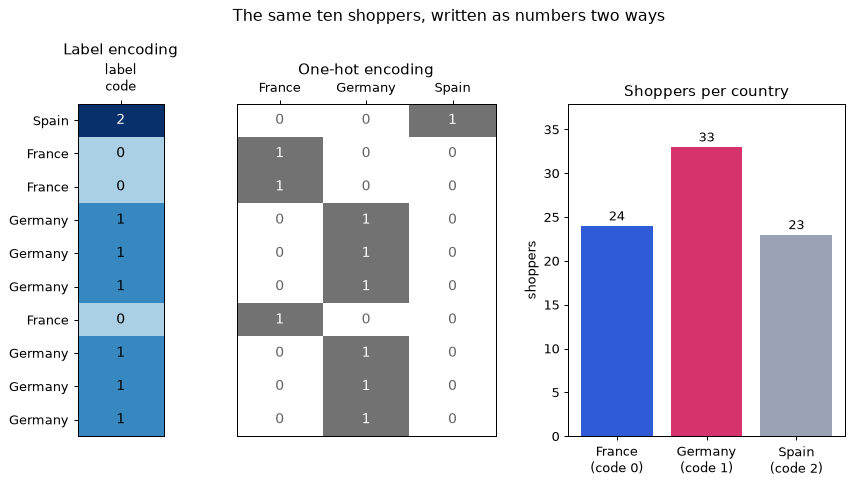

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

countries = list(le.classes_)
first = dataset['country'].head(10).reset_index(drop=True)
onehot = pd.get_dummies(first, dtype=int).reindex(columns=countries, fill_value=0)
label_codes = le.transform(first)

fig = plt.figure(figsize=(11, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 3, 3.2], wspace=0.35)

ax0 = fig.add_subplot(gs[0])
ax0.imshow(label_codes.reshape(-1, 1), cmap='Blues', vmin=-1, vmax=len(countries) - 1, aspect='auto')
for r, v in enumerate(label_codes):
    ax0.text(0, r, str(v), ha='center', va='center', fontsize=11, color='white' if v == len(countries) - 1 else 'black')
ax0.set_xticks([0], ['label\ncode'])
ax0.set_yticks(range(10), first)
ax0.set_title('Label encoding')
ax0.xaxis.tick_top()

ax1 = fig.add_subplot(gs[1])
ax1.imshow(onehot.values, cmap='Greys', vmin=0, vmax=1.6, aspect='auto')
for r in range(10):
    for c in range(len(countries)):
        v = onehot.values[r, c]
        ax1.text(c, r, str(v), ha='center', va='center', fontsize=11, color='white' if v else '#666666')
ax1.set_xticks(range(len(countries)), countries)
ax1.set_yticks([])
ax1.set_title('One-hot encoding')
ax1.xaxis.tick_top()

ax2 = fig.add_subplot(gs[2])
counts = dataset['country'].value_counts().reindex(countries)
bars = ax2.bar([f'{c}\n(code {i})' for i, c in enumerate(countries)], counts.values, color=[BLUE, PINK, '#9aa3b5'][:len(countries)])
ax2.bar_label(bars, padding=2)
ax2.set_ylabel('shoppers')
ax2.set_title('Shoppers per country')
ax2.set_ylim(0, counts.max() * 1.15)
fig.suptitle('The same ten shoppers, written as numbers two ways', y=1.1, fontsize=13)
plt.show()
